# Dar_007 — P1 Apollo seismic catalogs and waveform pilot
**D13:** two distinct published event catalogs; **D14:** original ATT timing pilot and an
additional actual MHZ seismic MiniSEED channel for the same station/day (S11, 1969 day 202).
The original download selected ATT, which is **timing**, not ground-motion amplitude.

Explore event classes, timing, location/depth uncertainty, timing continuity and an
uncorrected count-domain waveform spectrum. D23 ILSA remains login-gated.

In [3]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT / "darrel stuff/EDA/shared"), str(ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"),str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Scope and controls
Do not pool the two relocated catalogs as independent additional events. Decode event type
from each source label; retain artificial impacts separately. Event times use YYMMDDHHMM,
with seconds where supplied; unparseable/missing times remain NaT. MiniSEED segments remain
separate, without filling gaps. The [PSE SIS ?3.3.2](https://pds-geosciences.wustl.edu/lunar/urn-nasa-pds-apollo_pse/document/apollo_pse_description.pdf) specifies `-1`/`-1.0` as encoded missing samples, even inside a continuous MiniSEED trace. Count/mask them explicitly; never interpolate. PSD uses up to 10 minutes from the longest nonmissing MHZ block and
its true sample rate. No instrument response is supplied, so units stay counts/count²/Hz.

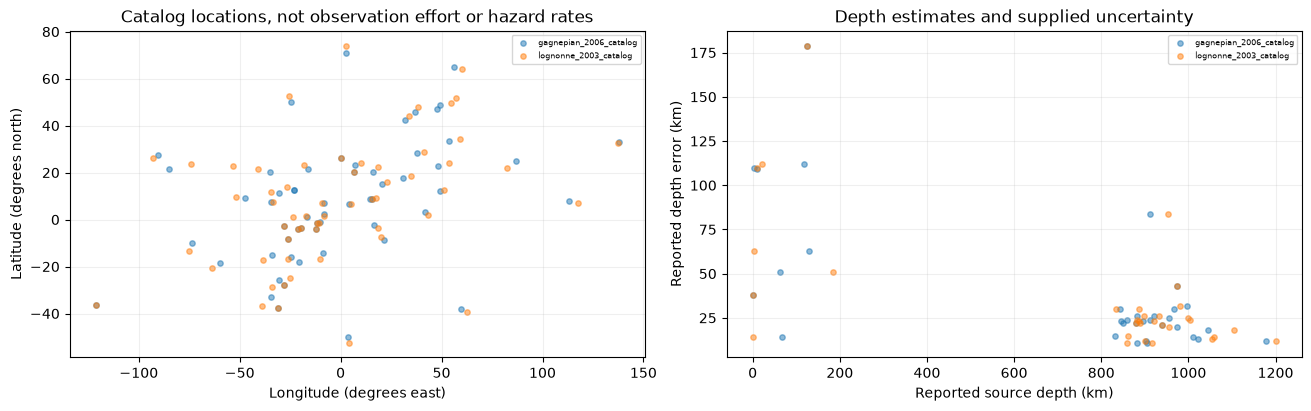

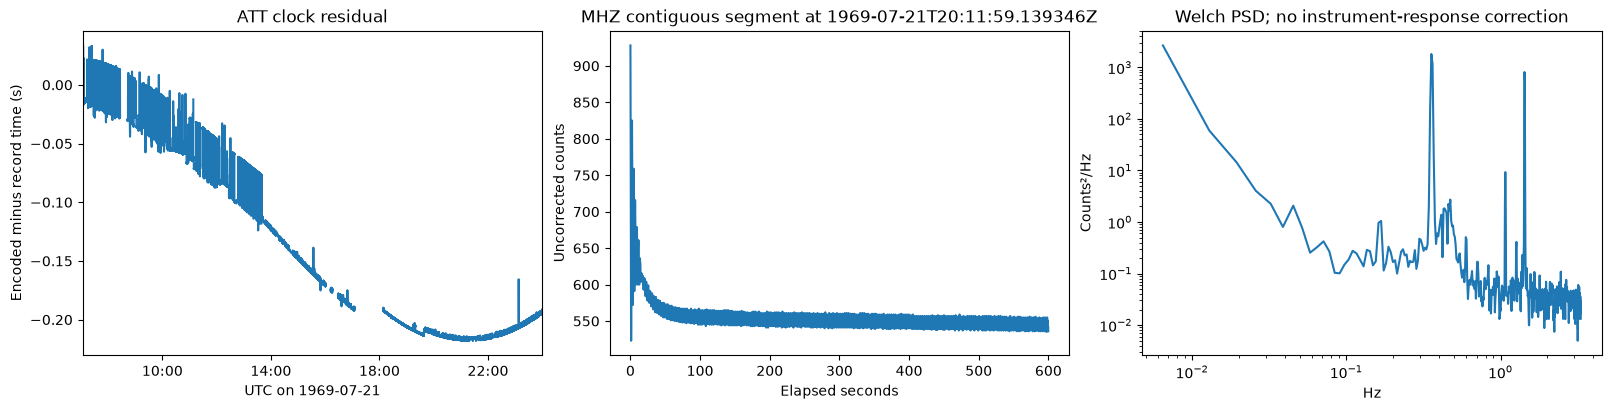

,catalog,event_class,catalog_entries
0,gagnepian_2006_catalog,artificial_or_other,7
1,gagnepian_2006_catalog,deep_moonquake,24
2,gagnepian_2006_catalog,natural_impact,19
3,gagnepian_2006_catalog,shallow_moonquake,8
4,lognonne_2003_catalog,artificial_or_other,8
5,lognonne_2003_catalog,deep_moonquake,24
6,lognonne_2003_catalog,natural_impact,19
7,lognonne_2003_catalog,shallow_moonquake,8


**Executed findings**

{'catalog_entries_per_source': {'gagnepian_2006_catalog': 58,
  'lognonne_2003_catalog': 59},
 'ATT_rows': 101005,
 'MHZ_segments': 1,
 'MHZ_samples': 404020,
 'inter_trace_gap_records': 0,
 'encoded_missing_MHZ_samples': 72084,
 'encoded_missing_ATT_samples': 17805,
 'encoded_missing_MHZ_runs': 279,
 'PSD_segment_samples': 3975,
 'holds': ['No response-corrected acceleration/velocity',
  'Catalogs are not independent event populations',
  'No local south-polar recurrence or structural certification',
  'D23 login required']}

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_007_research_seismic\20261109T151355955009Z_639f60


In [4]:
import obspy
from scipy.signal import welch
with Run(ROOT,'analysis/dar_007_research_seismic',{'datasets':['D13','D14'],'waveform_segment_seconds':600},'Moon/Dar_007_research_seismic.ipynb') as run:
    run.input(Path(research_p1_readers.__file__))
    catalogs=[];fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    for label in pilot_files(DATA,'D13','.xml'):
        pin(run,label);pin(run,label.with_suffix('.csv'));f=read_pds4(label);f['catalog']=label.stem
        f['event_class']=np.select([f.Type.eq('M'),f.Type.eq('SH'),f.Type.str.match(r'^A\d+')],['natural_impact','shallow_moonquake','deep_moonquake'],default='artificial_or_other')
        dates=f.Date.astype('Int64').astype(str).str.zfill(10)
        f['timestamp']=pd.to_datetime(dates,format='%y%m%d%H%M',errors='coerce',utc=True)
        if 'Seconds' in f:f['timestamp']=f.timestamp+pd.to_timedelta(f.Seconds,unit='s')
        f.to_csv(run.path(f'catalogs/{label.stem}.csv'),index=False);catalogs.append(f)
        located=f.loc[f.Lat.between(-90,90)&f.Long.between(-180,180)]
        axes[0].scatter(located.Long,located.Lat,s=15,alpha=.5,label=label.stem)
        depth=located.loc[located.event_class.isin(['shallow_moonquake','deep_moonquake'])]
        axes[1].scatter(depth.Depth,depth.Depth_err,s=15,alpha=.5,label=label.stem)
    axes[0].set(xlabel='Longitude (degrees east)',ylabel='Latitude (degrees north)',title='Catalog locations, not observation effort or hazard rates')
    axes[1].set(xlabel='Reported source depth (km)',ylabel='Reported depth error (km)',title='Depth estimates and supplied uncertainty')
    for ax in axes:ax.legend(fontsize=6);ax.grid(alpha=.2)
    savefig(run,fig,'seismic_catalog_locations_uncertainty')
    combined=pd.concat(catalogs,ignore_index=True)
    counts=combined.groupby(['catalog','event_class']).size().rename('catalog_entries').reset_index();counts.to_csv(run.path('catalog_class_counts.csv'),index=False)
    combined.assign(year=combined.timestamp.dt.year).groupby(['catalog','event_class','year'],dropna=False).size().rename('entries_not_rates').to_csv(run.path('catalog_counts_by_year.csv'))
    pin(run,DATA/'moon/eda_support/D14/apollo_pse_description.pdf')
    timing=pilot_files(DATA,'D14','.csv')[0];pin(run,timing);pin(run,timing.with_suffix('.xml'))
    # ATT GeoCSV's XML offset excludes comments/header; its Sample encodes Unix seconds.
    t=read_pds4(timing.with_suffix('.xml'));t['timestamp']=pd.to_datetime(t.Time,utc=True)
    t['recorded_unix_seconds']=t.timestamp.astype('int64')/1e9
    t['valid_clock_sample']=t.Sample.ne(-1)&t.Sample.notna()
    t['clock_residual_s']=(t.Sample-t.recorded_unix_seconds).where(t.valid_clock_sample)
    t['delta_sample_s']=t.Sample.diff().where(t.valid_clock_sample & t.valid_clock_sample.shift(fill_value=False))
    t['delta_record_s']=t.timestamp.diff().dt.total_seconds()
    t[['timestamp','clock_residual_s','delta_sample_s','delta_record_s']].to_csv(run.path('att_timing_diagnostics.csv'),index=False)
    wave=DATA/'moon/eda_support/D14/xa.s11.00.mhz.1969.202.0.mseed';pin(run,wave);pin(run,wave.with_suffix('.xml'))
    stream=obspy.read(str(wave));traces=[]
    for trace in stream:
        if trace.stats.channel!='MHZ':raise ValueError('Expected actual MHZ seismic data, not timing channel')
        traces.append({'trace_id':trace.id,'start':str(trace.stats.starttime),'end':str(trace.stats.endtime),'samples':trace.stats.npts,'sample_rate_hz':trace.stats.sampling_rate,'encoded_missing_samples':int(np.sum(trace.data==-1))})
    pd.DataFrame(traces).to_csv(run.path('waveform_segments.csv'),index=False)
    gaps=stream.get_gaps();run.path('inter_trace_gaps.json').write_text(json.dumps(gaps,default=str,indent=2),encoding='utf-8')
    segments=[];missing_intervals=[]
    for candidate in stream:
        encoded=np.ma.masked_equal(candidate.data,-1)
        segments.extend((candidate,span) for span in np.ma.clump_unmasked(encoded))
        for span in np.ma.clump_masked(encoded):
            missing_intervals.append({'trace_id':candidate.id,'start_sample':span.start,'stop_exclusive_sample':span.stop,'missing_samples':span.stop-span.start})
    pd.DataFrame(missing_intervals).to_csv(run.path('encoded_missing_intervals.csv'),index=False)
    if not segments:raise ValueError('No nonmissing contiguous seismic samples')
    trace,span=max(segments,key=lambda item:item[1].stop-item[1].start)
    rate=float(trace.stats.sampling_rate)
    segment_start=trace.stats.starttime+span.start/rate
    values=np.ma.asarray(trace.data[span.start:min(span.stop,span.start+int(600*rate))]).astype(float)
    if np.ma.getmaskarray(values).any():raise ValueError('Masked samples in selected contiguous waveform segment')
    frequency,power=welch(np.asarray(values),fs=rate,nperseg=min(1024,len(values)),detrend='constant')
    pd.DataFrame({'frequency_hz':frequency,'uncorrected_counts2_per_Hz':power}).to_csv(run.path('waveform_count_domain_psd.csv'),index=False)
    fig,axes=plt.subplots(1,3,figsize=(16,4),layout='constrained')
    from matplotlib.dates import DateFormatter,HourLocator
    axes[0].plot(t.timestamp,t.clock_residual_s)
    axes[0].set(title='ATT clock residual',ylabel='Encoded minus record time (s)',xlabel='UTC on 1969-07-21')
    axes[0].set_xlim(t.timestamp.min(),t.timestamp.max())
    axes[0].xaxis.set_major_locator(HourLocator(interval=4));axes[0].xaxis.set_major_formatter(DateFormatter('%H:%M'))
    axes[1].plot(np.arange(len(values))/rate,values);axes[1].set(title=f'MHZ contiguous segment at {segment_start}',xlabel='Elapsed seconds',ylabel='Uncorrected counts')
    axes[2].loglog(frequency[1:],power[1:]);axes[2].set(title='Welch PSD; no instrument-response correction',xlabel='Hz',ylabel='Counts²/Hz')
    savefig(run,fig,'apollo_timing_waveform_psd')
    display(counts)
    save_findings(run,{'catalog_entries_per_source':{f.catalog.iloc[0]:len(f) for f in catalogs},'ATT_rows':len(t),'MHZ_segments':len(traces),
        'MHZ_samples':sum(x['samples'] for x in traces),'inter_trace_gap_records':len(gaps),'encoded_missing_MHZ_samples':sum(x['encoded_missing_samples'] for x in traces),
        'encoded_missing_ATT_samples':int((~t.valid_clock_sample).sum()),'encoded_missing_MHZ_runs':len(missing_intervals),'PSD_segment_samples':len(values),
        'holds':['No response-corrected acceleration/velocity','Catalogs are not independent event populations','No local south-polar recurrence or structural certification','D23 login required']})
OUT=run.directory;print('Completed:',OUT)

## Stage 3 role
These results expose seismic evidence coverage, classification and instrument limitations.
They do not assign south-polar recurrence, local shaking design loads or a safe structure
rating. Response metadata and a documented event-window join are required before physical
amplitudes or event-related spectral comparisons. No unknown transient is labelled a quake.

The chosen segment contains a transient; its PSD is descriptive spectral content, not a validated stationary noise floor or an identified moonquake.